In [1]:
from pathlib import Path
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook", font_scale=1.0)
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 15)
pd.set_option("display.precision", 3)
RANDOM_STATE = 42

In [2]:
df= pd.read_csv("data clean/data clean.csv")


In [3]:
DATA_PATH = Path("chronic_kidney_disease.csv")
TARGET = "Chronic_Kidney_Disease"

NUMERIC_FEATURES = [
    "Age",
    "Blood_Pressure",
    "Specific_Gravity",
    "Albumin",
    "Sugar",
    "Blood_Glucose_Random",
    "Blood_Urea",
    "Serum_Creatinine",
    "Sodium",
    "Potassium",
    "Hemoglobin",
    "Packed_Cell_Volume",
    "White_Blood_Cell_Count",
    "Red_Blood_Cell_Count"
]

CATEGORICAL_FEATURES = [
    "Red_Blood_Cells",
    "Pus_Cells",
    "Pus_Cell_Clumps",
    "Bacteria",
    "Appetite",
    "Age_Group",
    "Blood_Pressure_Category",
    "Blood_Glucose_Category"
]

ID_COLUMNS = ["Patient_ID"]
DATETIME_COLUMNS = []
EXCLUDED_COLUMNS = []  
TARGET_LABELS = {
    0: "No chronic kidney disease",
    1: "Chronic kidney disease"
}

POSITIVE_CLASS = 1 

In [4]:
for col in CATEGORICAL_FEATURES:
    print(f"\n{col}")
    display(df[col].value_counts(dropna=False).rename("rows").to_frame())

if NUMERIC_FEATURES:
    display(df[NUMERIC_FEATURES].describe().T)

    display(pd.DataFrame({
        "most_frequent_value": [
            df[c].mode().iloc[0] if not df[c].mode().empty else np.nan
            for c in NUMERIC_FEATURES
        ],
        "frequency_pct": [
            100 * df[c].value_counts(normalize=True).iloc[0]
            if df[c].notna().any() else np.nan
            for c in NUMERIC_FEATURES
        ]
    }, index=NUMERIC_FEATURES))


Red_Blood_Cells


,rows
Red_Blood_Cells,
normal,7689
anormal,7360



Pus_Cells


,rows
Pus_Cells,
normal,7654
anormal,7395



Pus_Cell_Clumps


...

,rows
Blood_Pressure_Category,
normal,9265
low,5160
elevated,339
high,285



Blood_Glucose_Category


,rows
Blood_Glucose_Category,
normal,7528
high,4266
elevated,3255


,count,mean,std,min,25%,50%,75%,max
Age,15049.0,52.101,17.555,2.000,45.00,55.000,65.00,90.0
Blood_Pressure,15049.0,93.233,19.907,50.000,80.00,94.000,107.00,180.0
Specific_Gravity,15049.0,6.468,5.817,1.005,1.02,1.025,12.35,15.0
Albumin,15049.0,228.292,314.184,0.000,0.00,1.000,452.20,989.9
Sugar,15049.0,154.295,248.574,0.000,0.00,1.000,200.00,1000.0
Blood_Glucose_Random,15049.0,157.609,62.356,70.000,105.00,139.000,208.00,300.0
Blood_Urea,15049.0,59.641,42.506,10.000,25.00,40.000,93.50,200.0
Serum_Creatinine,15040.0,3.224,5.480,0.400,0.93,1.400,3.25,76.0
Sodium,15049.0,138.584,5.823,120.000,135.00,139.000,143.00,150.0
Potassium,15049.0,5.385,0.860,3.500,4.79,5.400,6.09,7.5


,most_frequent_value,frequency_pct
Age,45.000,4.698
Blood_Pressure,70.000,13.529
Specific_Gravity,1.017,5.083
Albumin,1.000,25.789
Sugar,0.000,25.603
Blood_Glucose_Random,140.000,0.917
Blood_Urea,24.000,1.794
Serum_Creatinine,1.200,6.310
Sodium,138.000,5.203
Potassium,5.900,1.967


In [5]:
TARGET_LABELS = {
    0: "No chronic kidney disease",
    1: "Chronic kidney disease"
}

POSITIVE_CLASS = 1

print(f"Rows excluded from class comparisons because target is missing: {df[TARGET].isna().sum():,}")
df = df.loc[df[TARGET].notna()].copy()

assert not df.empty, "No labeled rows remain."

if NUMERIC_FEATURES:
    assert not np.isinf(df[NUMERIC_FEATURES].to_numpy(dtype=float)).any(), "Investigate infinite values."
    NUMERIC_FEATURES = [c for c in NUMERIC_FEATURES if df[c].notna().any()]
    print("Numerical features with at least one observed value:", NUMERIC_FEATURES)

observed_classes = sorted(df[TARGET].unique(), key=str)
label_lookup = {value: str(TARGET_LABELS.get(value, value)) for value in observed_classes}

assert len(set(label_lookup.values())) == len(label_lookup), "Target display labels must be distinct."

CLASS_COL = "__target_label__"
assert CLASS_COL not in df.columns
df[CLASS_COL] = df[TARGET].map(label_lookup)

class_order = [label_lookup[v] for v in observed_classes]
class_colors = dict(zip(class_order, sns.color_palette("colorblind", len(class_order))))
IS_BINARY = len(observed_classes) == 2 and POSITIVE_CLASS in observed_classes

for col in CATEGORICAL_FEATURES:
    df[col] = df[col].astype("string").fillna("<Missing>")

category_orders = {c: df[c].value_counts().index.tolist() for c in CATEGORICAL_FEATURES}

print(f"Analysis population: {len(df):,} rows; classes: {class_order}")

Rows excluded from class comparisons because target is missing: 0


Numerical features with at least one observed value: ['Age', 'Blood_Pressure', 'Specific_Gravity', 'Albumin', 'Sugar', 'Blood_Glucose_Random', 'Blood_Urea', 'Serum_Creatinine', 'Sodium', 'Potassium', 'Hemoglobin', 'Packed_Cell_Volume', 'White_Blood_Cell_Count', 'Red_Blood_Cell_Count']
Analysis population: 15,049 rows; classes: ['no', 'si']


In [6]:
class_colors = {
    0: "#4E79A7",
    1: "#E15759"
}


def label_bars(ax, fmt="%.0f"):
    for container in ax.containers:
        ax.bar_label(container, fmt=fmt)


def subplot_grid(n, ncols=2, width=6, height=4):
    """return a figure and n usable axes; hide any unused panels."""
    ncols = min(ncols, max(1, n))
    nrows = int(np.ceil(max(1, n) / ncols))

    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(width * ncols, height * nrows),
        squeeze=False,
        constrained_layout=True
    )

    flat = axes.ravel()

    for ax in flat[n:]:
        ax.set_visible(False)

    return fig, flat[:n]

Understand the target first

In [7]:
target_counts = df[CLASS_COL].value_counts().reindex(class_order)
target_summary = pd.DataFrame({
    "rows": target_counts,
    "percent": target_counts / len(df) * 100
})

print(target_counts)
print(target_summary)

__target_label__
no    7696
si    7353
Name: count, dtype: int64
                  rows  percent
__target_label__               
no                7696    51.14
si                7353    48.86


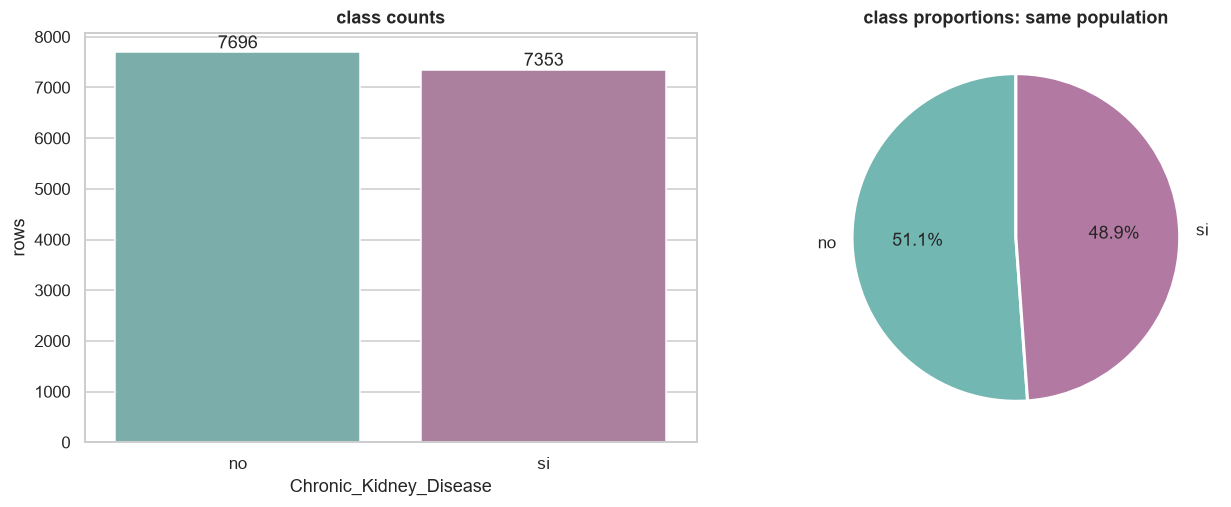

majority-class baseline on these rows: 51.14%


In [8]:
class_colors = {
    "no": "#72B7B2",
    "si": "#B279A2"
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)

sns.countplot(
    data=df,
    x=CLASS_COL,
    order=class_order,
    palette=class_colors,
    hue=CLASS_COL,
    hue_order=class_order,
    legend=False,
    ax=axes[0]
)

axes[0].set(title="class counts", xlabel=TARGET, ylabel="rows")
label_bars(axes[0], "%.0f")

if len(class_order) <= 5:
    axes[1].pie(
        target_counts,
        labels=class_order,
        autopct="%1.1f%%",
        startangle=90,
        colors=[class_colors[c] for c in class_order],
        wedgeprops={"edgecolor": "white", "linewidth": 2}
    )
    axes[1].set_title("class proportions: same population")
else:
    axes[1].axis("off")
    axes[1].text(
        0, 0.5,
        "pie omitted: use the countplot and percentage table for many classes."
    )

plt.show()

print(f"majority-class baseline on these rows: {target_counts.max() / len(df):.2%}")

One feature at a time: numerical distributions

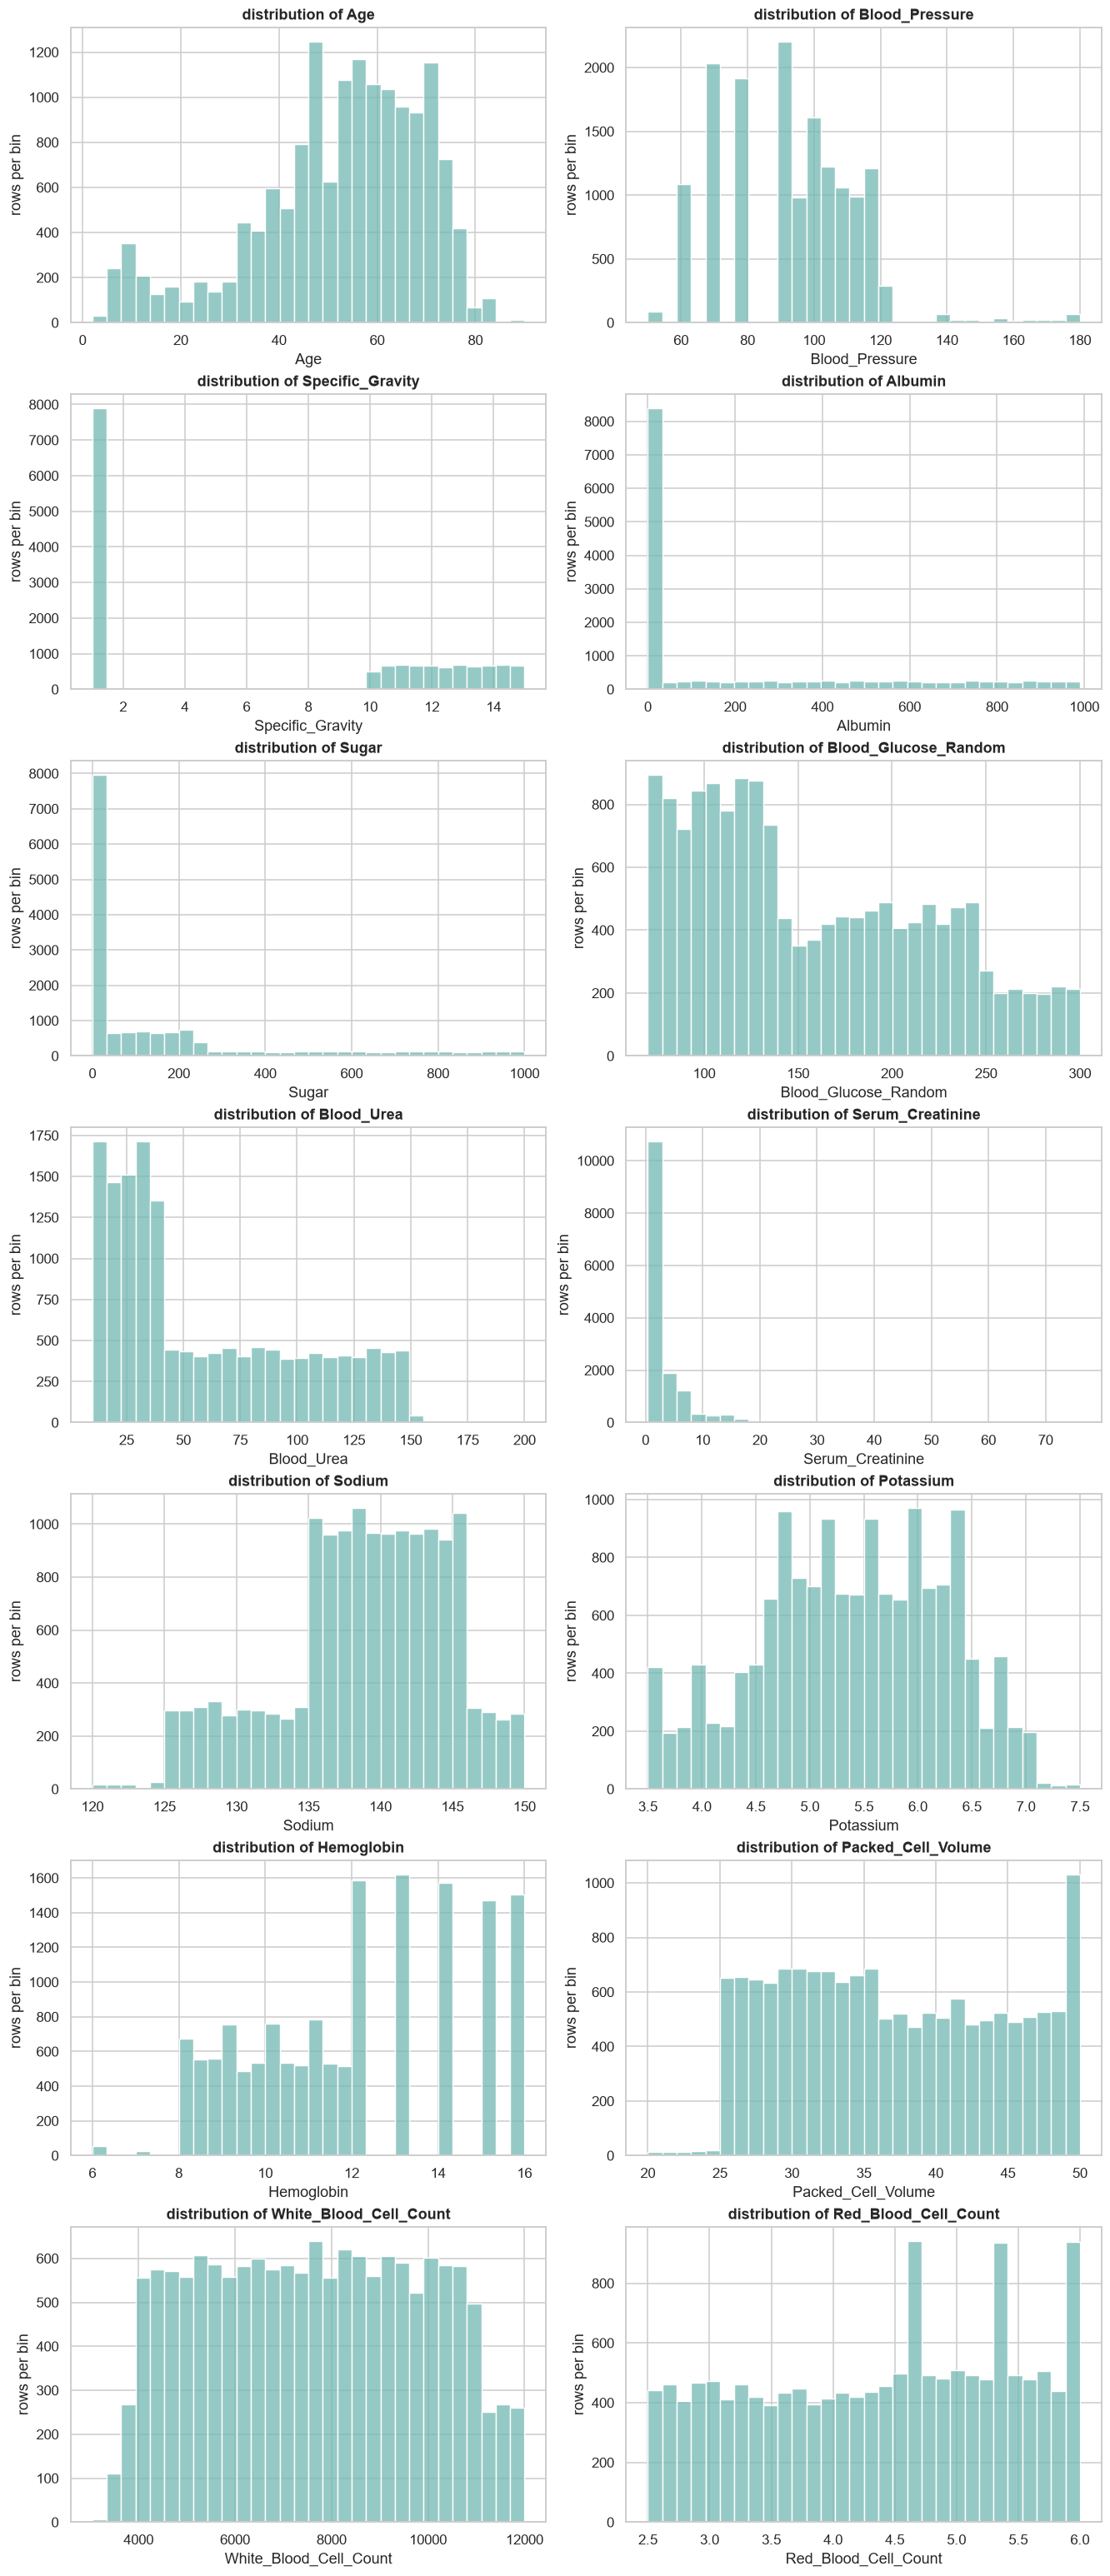

In [9]:
if NUMERIC_FEATURES:
    fig, axes = subplot_grid(len(NUMERIC_FEATURES))

    for ax, col in zip(axes, NUMERIC_FEATURES):
        sns.histplot(
            data=df,
            x=col,
            bins=30,
            color="#72B7B2",
            ax=ax
        )
        ax.set(title=f"distribution of {col}", ylabel="rows per bin")

    plt.show()

One feature at a time: categorical frequencies

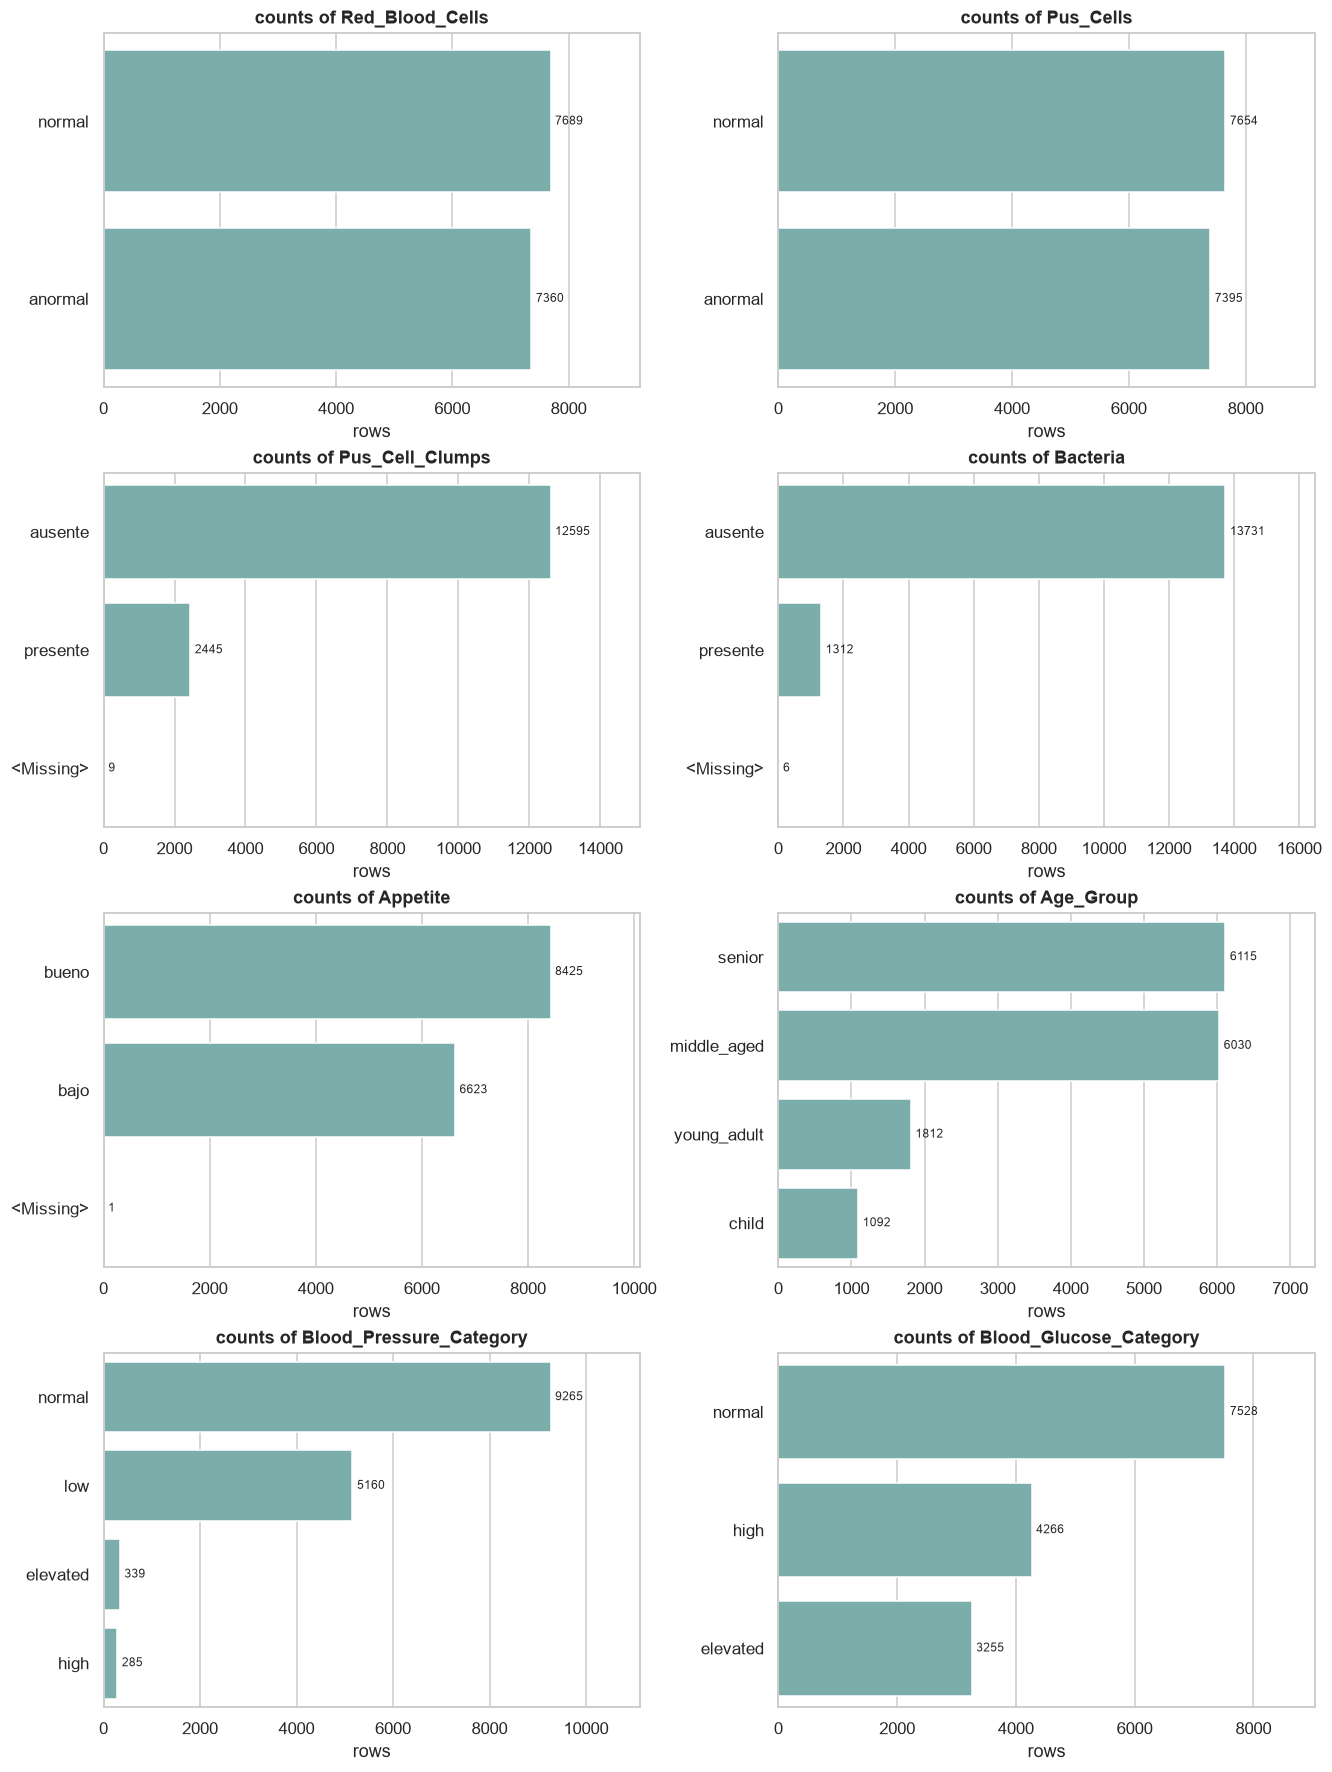

In [10]:
if CATEGORICAL_FEATURES:
    fig, axes = subplot_grid(len(CATEGORICAL_FEATURES))
    for ax, col in zip(axes, CATEGORICAL_FEATURES):
        sns.countplot(data=df, y=col, order=category_orders[col], color="#72B7B2", ax=ax)
        ax.set(title=f"counts of {col}", xlabel="rows", ylabel="")
        for container in ax.containers:
            ax.bar_label(container, fmt="%.0f", fontsize=8, padding=3)
        ax.margins(x=0.2)
    plt.show()

Boxplots and possible outliers

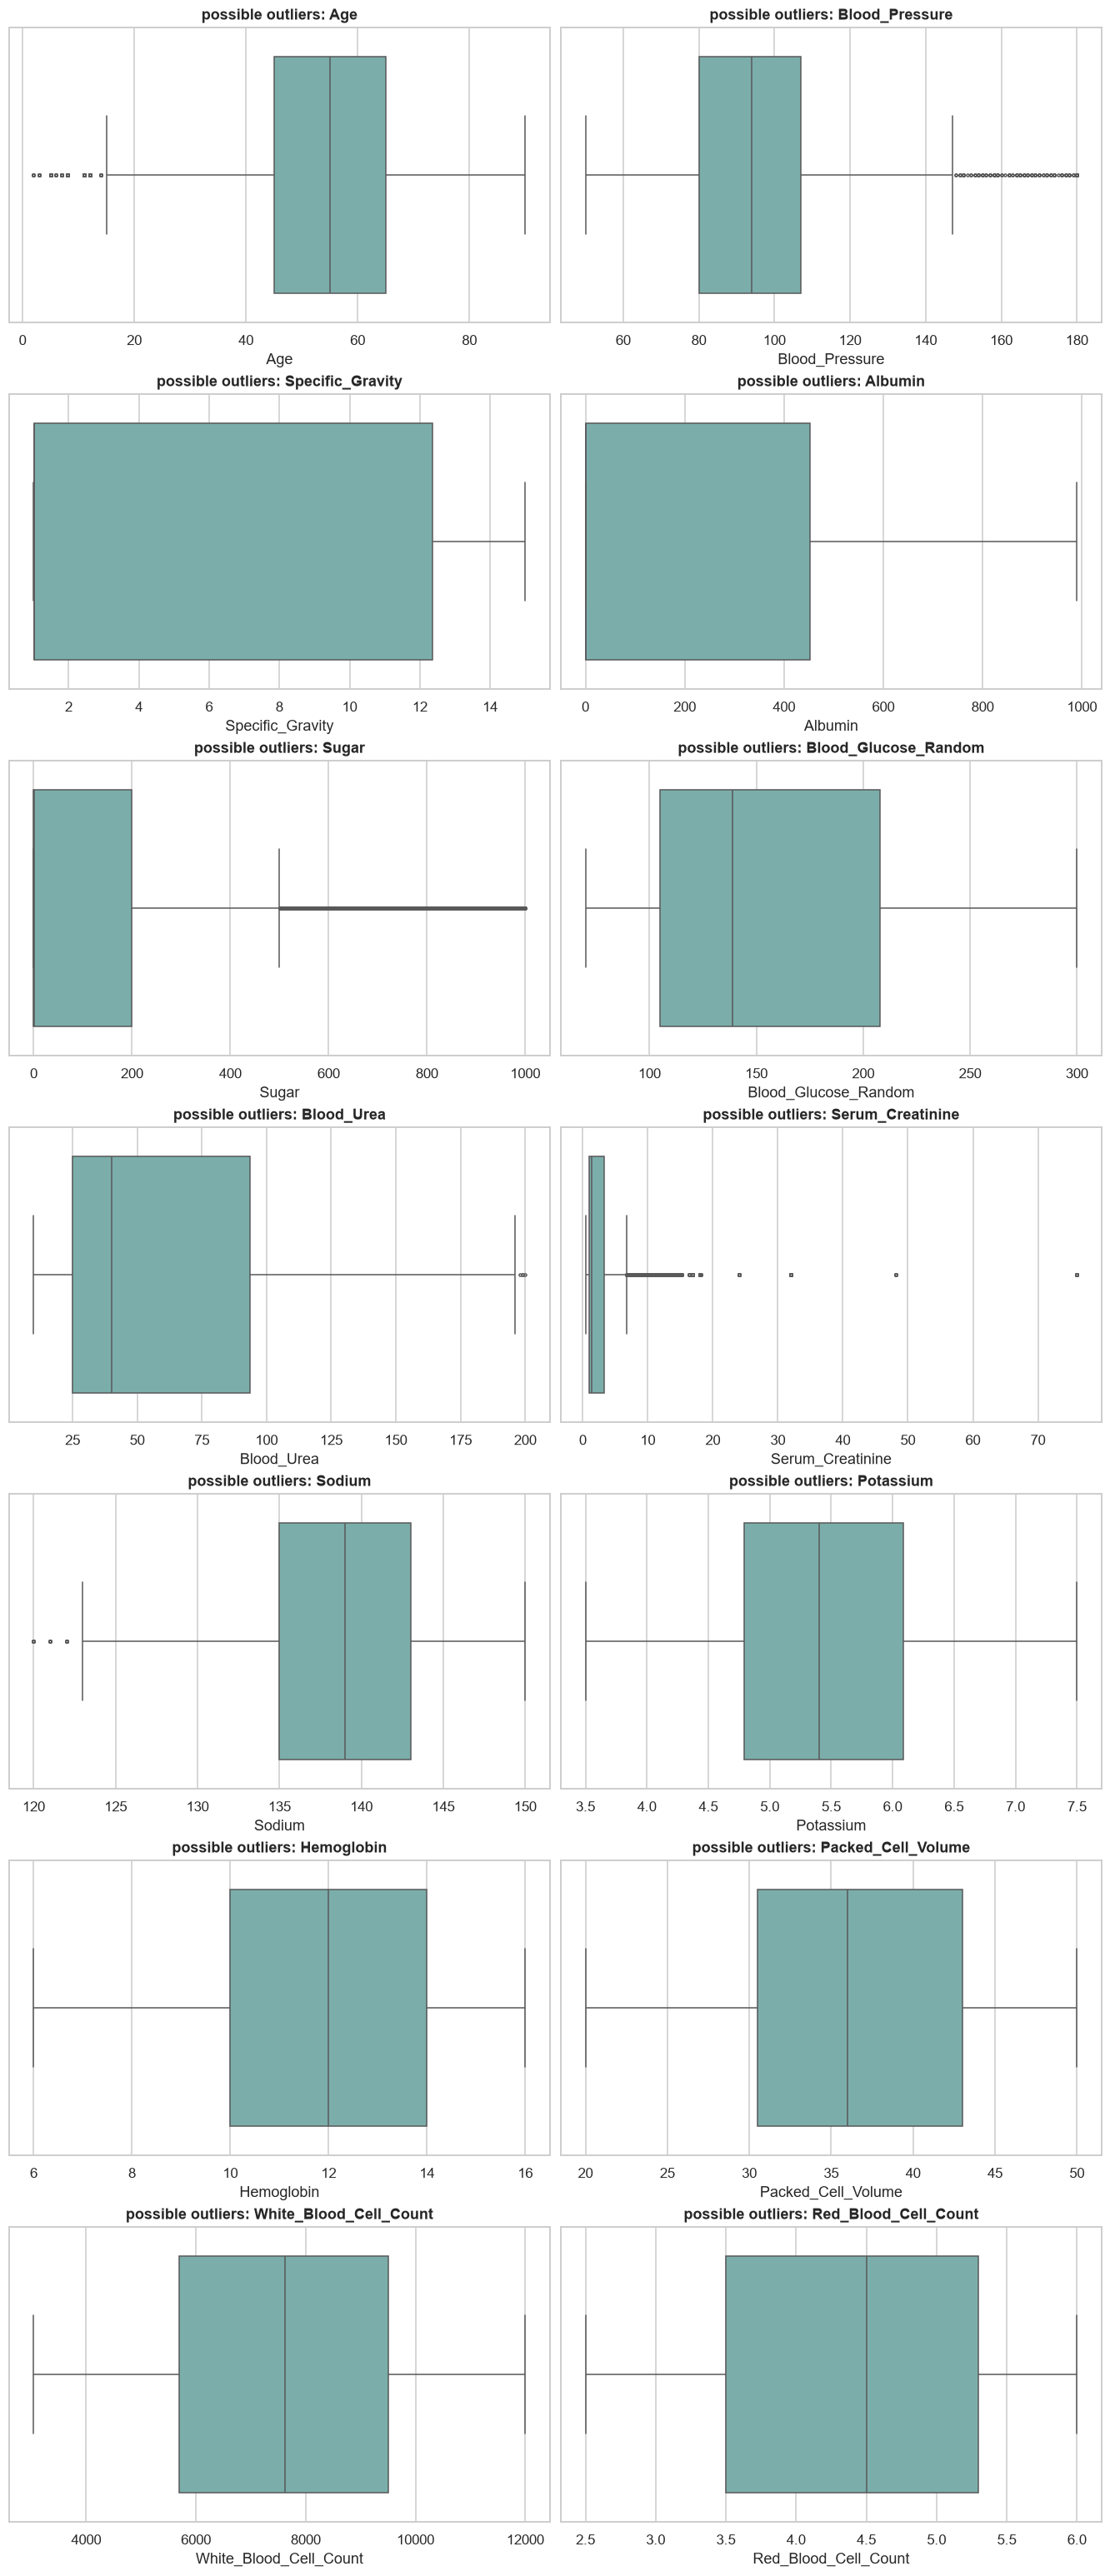

               feature      Q1      Q3     IQR  lower_fence  upper_fence  flagged_n  observed_n  flagged_pct
                   Age   45.00   65.00   20.00       15.000       95.000        850       15049        5.648
        Blood_Pressure   80.00  107.00   27.00       39.500      147.500        200       15049        1.329
      Specific_Gravity    1.02   12.35   11.33      -15.975       29.345          0       15049        0.000
               Albumin    0.00  452.20  452.20     -678.300     1130.500          0       15049        0.000
                 Sugar    0.00  200.00  200.00     -300.000      500.000       1808       15049       12.014
  Blood_Glucose_Random  105.00  208.00  103.00      -49.500      362.500          0       15049        0.000
            Blood_Urea   25.00   93.50   68.50      -77.750      196.250          4       15049        0.027
      Serum_Creatinine    0.93    3.25    2.32       -2.550        6.730       1535       15040       10.206
                Sod

In [11]:
outlier_rows = []

if NUMERIC_FEATURES:
    fig, axes = subplot_grid(len(NUMERIC_FEATURES))

    for ax, col in zip(axes, NUMERIC_FEATURES):
        sns.boxplot(data=df, x=col, color="#72B7B2", fliersize=2, ax=ax)
        ax.set_title(f"possible outliers: {col}")

        x = df[col].dropna()
        q1, q3 = x.quantile([0.25, 0.75])
        iqr = q3 - q1
        lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr

        flagged = (x < lower) | (x > upper)

        outlier_rows.append({
            "feature": col,
            "Q1": q1,
            "Q3": q3,
            "IQR": iqr,
            "lower_fence": lower,
            "upper_fence": upper,
            "flagged_n": int(flagged.sum()),
            "observed_n": len(x),
            "flagged_pct": flagged.mean() * 100
        })

    plt.show()

outlier_summary = pd.DataFrame(outlier_rows)
print(outlier_summary.to_string(index=False))

print("flagged rows have been retained.")

Numerical feature versus target: compare entire distributions

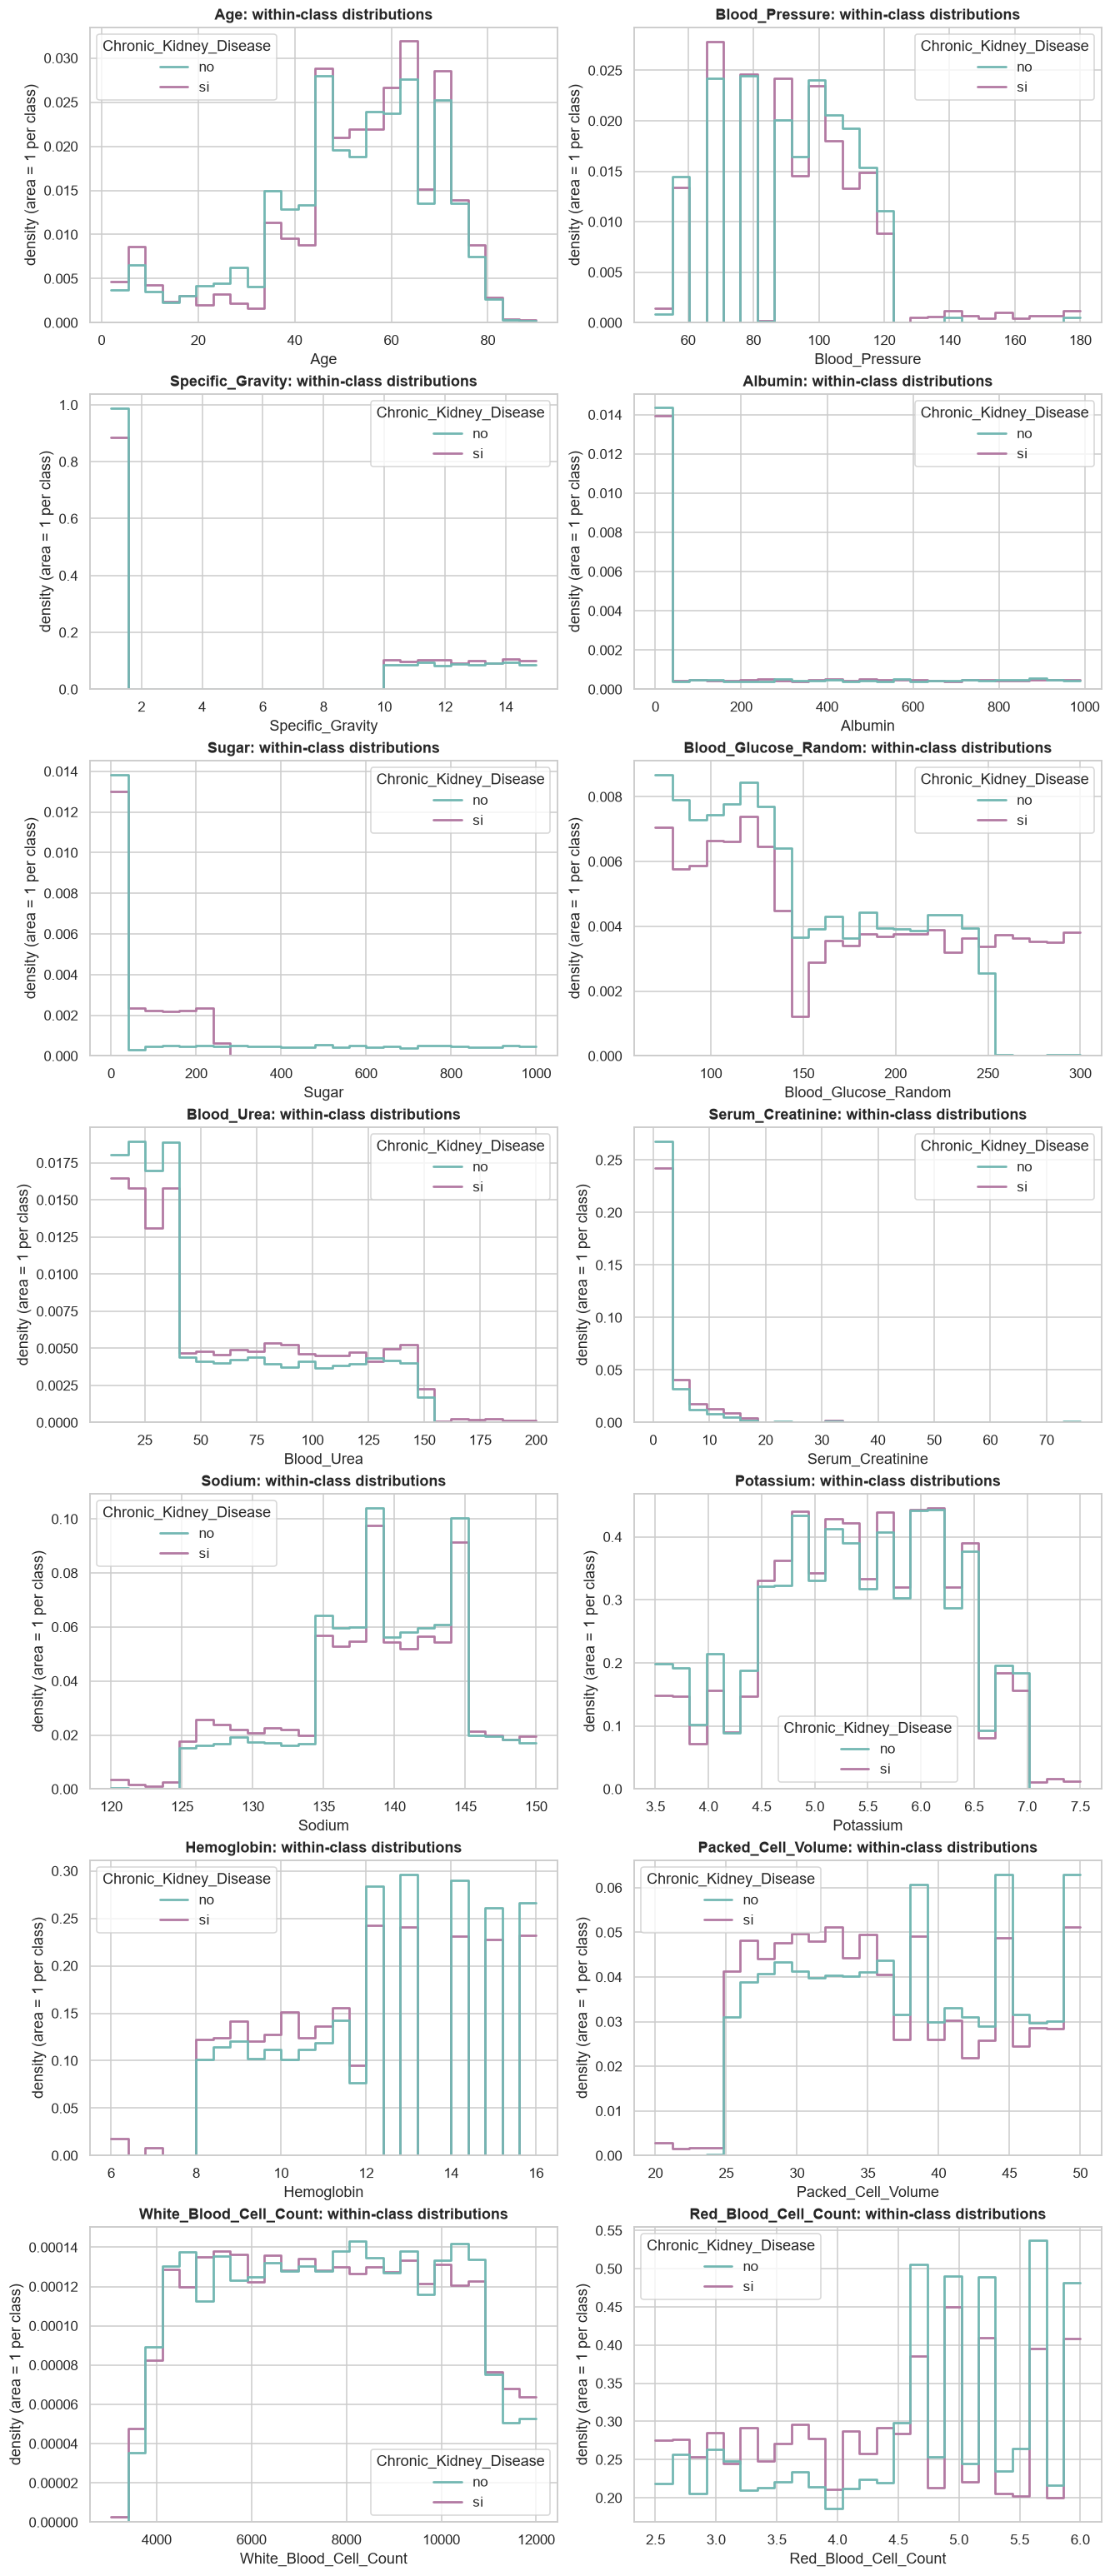

In [12]:
if NUMERIC_FEATURES:
    fig, axes = subplot_grid(len(NUMERIC_FEATURES))
    for ax, col in zip(axes, NUMERIC_FEATURES):
        sns.histplot(
            data=df,
            x=col,
            hue=CLASS_COL,
            hue_order=class_order,
            palette=class_colors,
            bins=25,
            stat="density",
            common_norm=False,
            common_bins=True,
            element="step",
            fill=False,
            linewidth=1.8,
            ax=ax
        )
        ax.set(
            title=f"{col}: within-class distributions",
            ylabel="density (area = 1 per class)"
        )

        if ax.get_legend() is not None:
            ax.get_legend().set_title(TARGET)

    plt.show()

Mean, minimum, and maximum of every numerical feature by target class

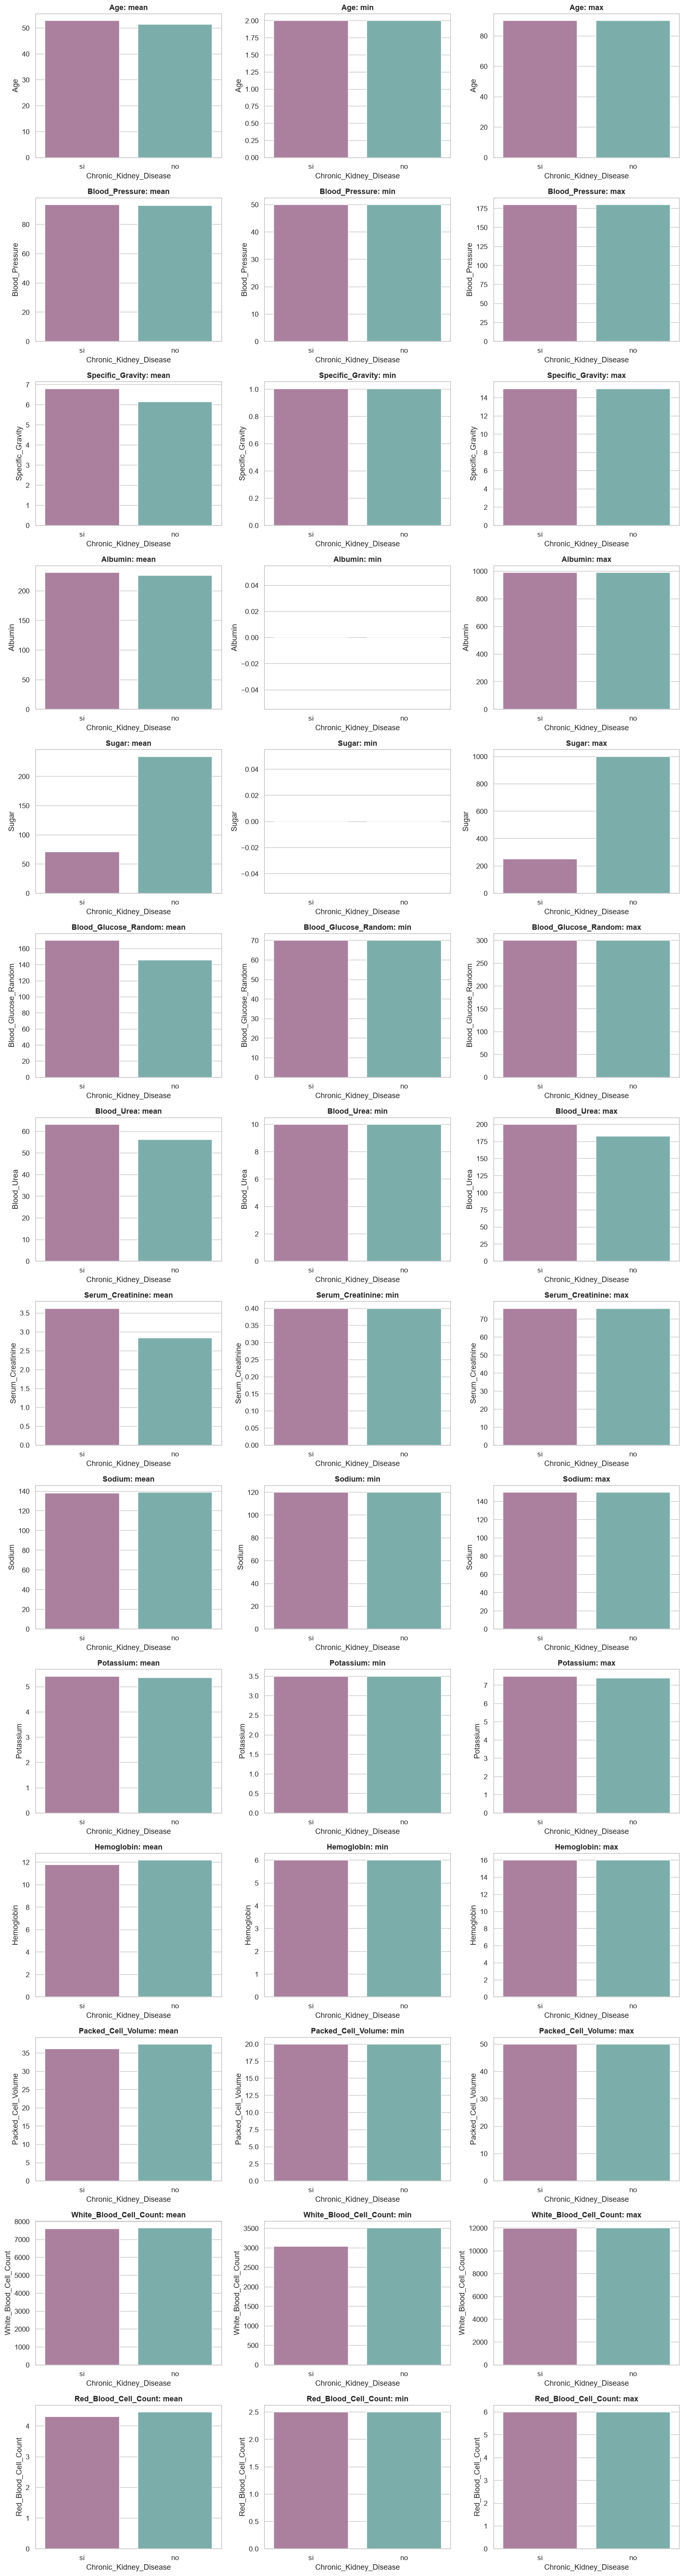

In [13]:
statistics = ["mean", "min", "max"]

plt.figure(figsize=(15, 4 * len(NUMERIC_FEATURES)))

plot_number = 1

for column in NUMERIC_FEATURES:
    for statistic in statistics:

        # select the next subplot.
        plt.subplot(len(NUMERIC_FEATURES), 3, plot_number)

        # calculate and plot the chosen statistic for each target class.
        sns.barplot(
            data=df,
            x=CLASS_COL,
            y=column,
            estimator=statistic,
            errorbar=None,
            hue=CLASS_COL,
            hue_order=class_order,
            palette=class_colors,
            legend=False
        )

        plt.title(f"{column}: {statistic}")
        plt.xlabel(TARGET)
        plt.ylabel(column)

        # plt.ylim(bottom=5)

        plot_number += 1

plt.tight_layout()
plt.show()

Categorical feature versus target: counts and rates answer different questions

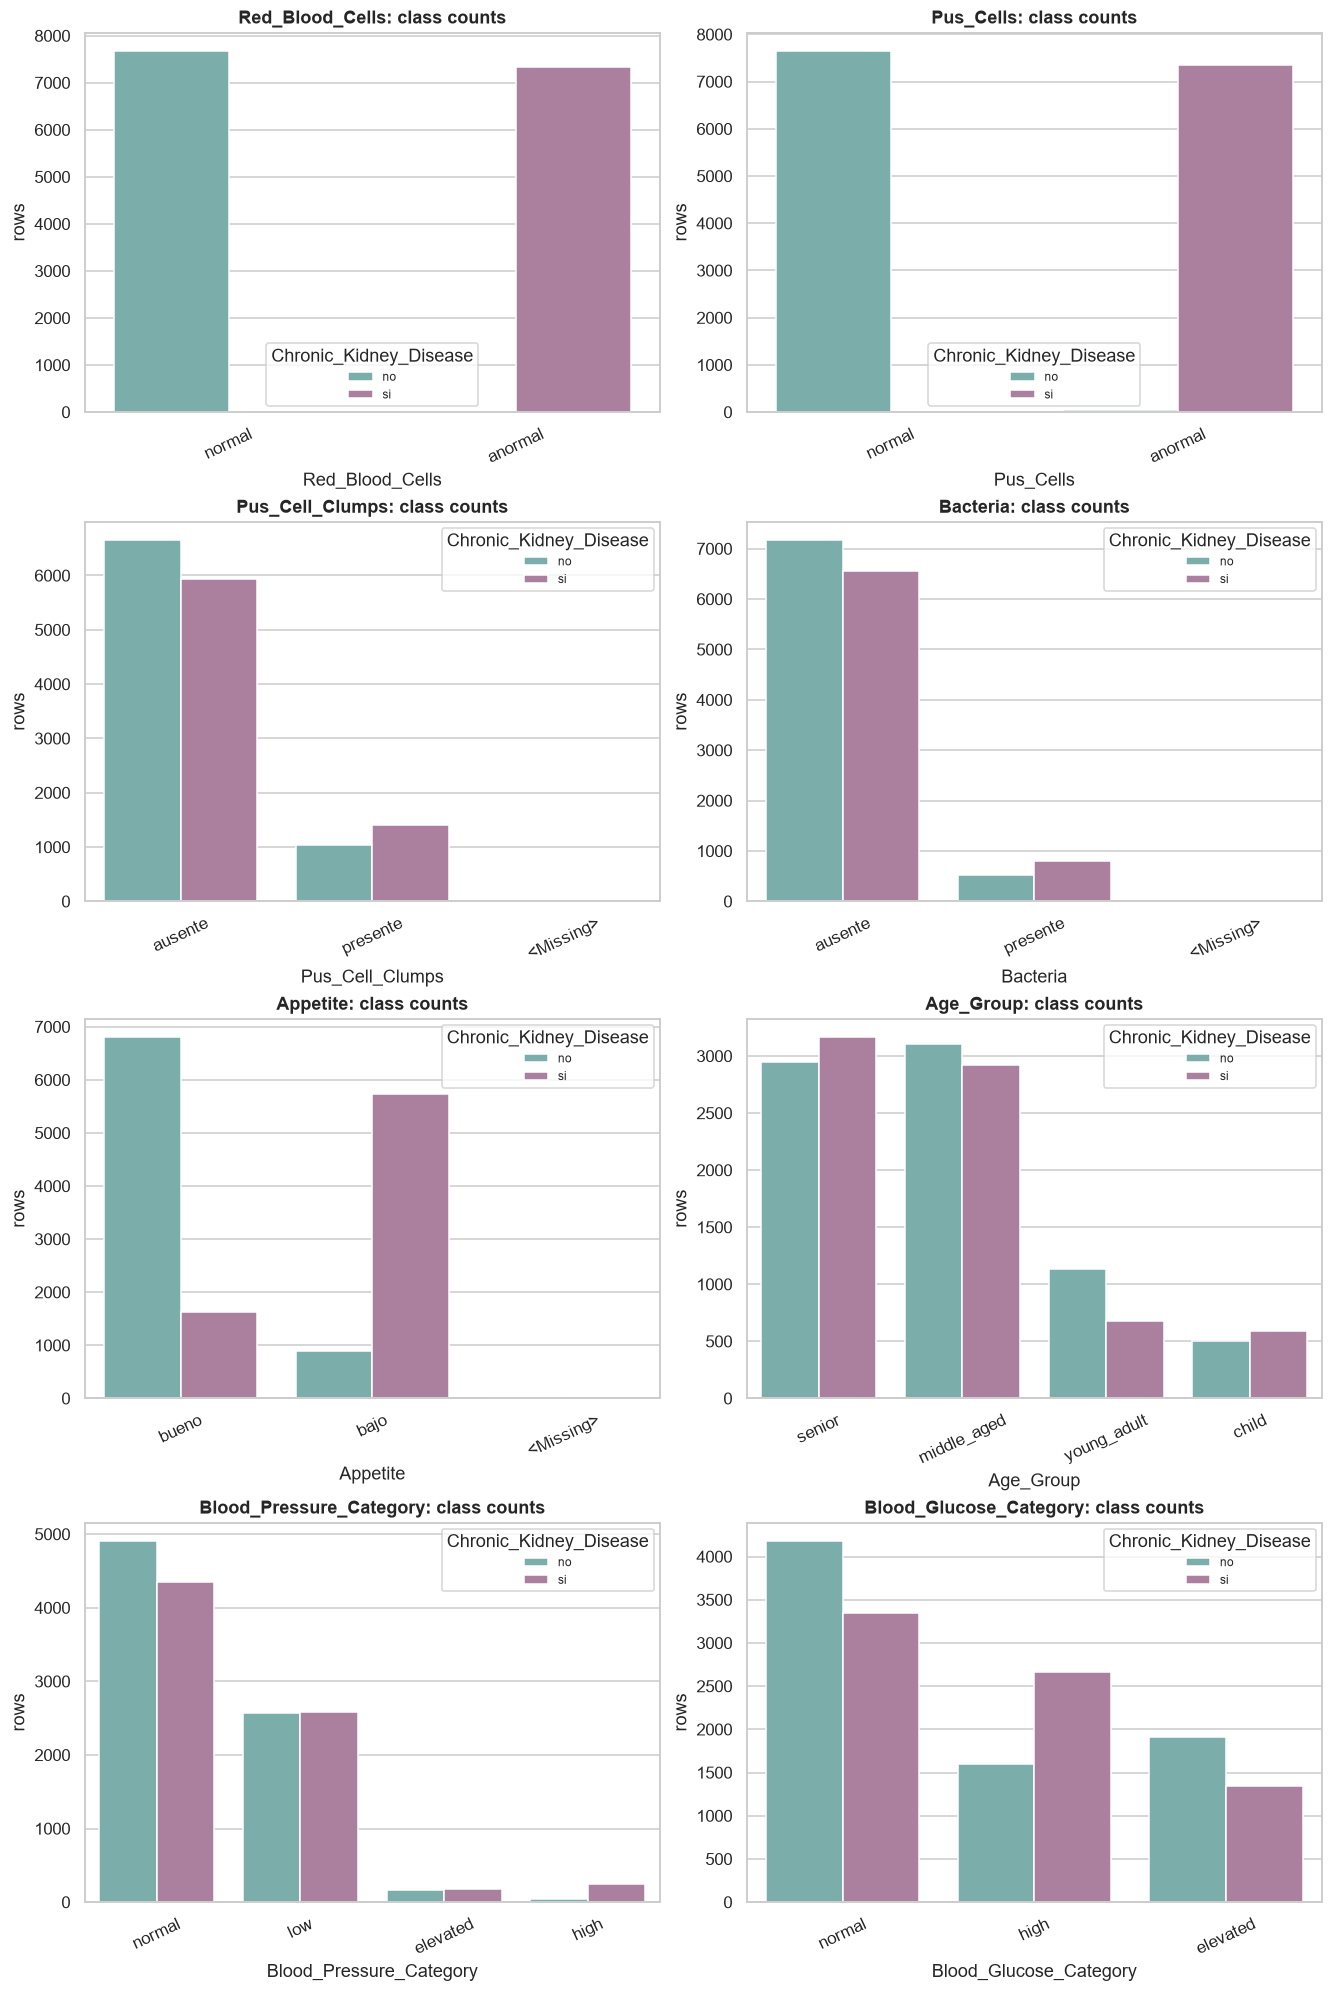

In [15]:
if CATEGORICAL_FEATURES:
    fig, axes = subplot_grid(len(CATEGORICAL_FEATURES), height=4.5)

    for ax, col in zip(axes, CATEGORICAL_FEATURES):
        sns.countplot(
            data=df,
            x=col,
            hue=CLASS_COL,
            order=category_orders[col],
            hue_order=class_order,
            palette=class_colors,
            ax=ax
        )

        ax.set(title=f"{col}: class counts", ylabel="rows")
        ax.tick_params(axis="x", rotation=25)
        ax.legend(title=TARGET, fontsize=8)

    plt.show()